# DA 2013 – Take-Home Assignment 02
## Data Cleaning and Management in Practice

**Research question:** How are economic development and social conditions associated with happiness?

**Datasets:** World Happiness Report data (2015–2019) and Life Expectancy data.



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
df_2015 = pd.read_csv("2015.csv")
df_2016 = pd.read_csv("2016.csv")
df_2017 = pd.read_csv("2017.csv")
df_2018 = pd.read_csv("2018.csv")
df_2019 = pd.read_csv("2019.csv")
life_raw = pd.read_csv("life-expectancy.csv")

print("2015:", df_2015.shape)
print("2016: ", df_2016.shape)
print("2017: ", df_2017.shape)
print("2018: ", df_2018.shape)
print("2019: ", df_2019.shape)
print("Life expectancy: ", life_raw.shape)

2015: (158, 12)
2016:  (157, 13)
2017:  (155, 12)
2018:  (156, 9)
2019:  (156, 9)
Life expectancy:  (21565, 4)


In [11]:
display(df_2015.head())
display(df_2019.head())
display(life_raw.head())

,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


,Entity,Code,Year,Life expectancy
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975


In [12]:
df_2015.info()
life_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        158 non-null    object 
 1   Region                         158 non-null    object 
 2   Happiness Rank                 158 non-null    int64  
 3   Happiness Score                158 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       158 non-null    float64
 6   Family                         158 non-null    float64
 7   Health (Life Expectancy)       158 non-null    float64
 8   Freedom                        158 non-null    float64
 9   Trust (Government Corruption)  158 non-null    float64
 10  Generosity                     158 non-null    float64
 11  Dystopia Residual              158 non-null    float64
dtypes: float64(9), int64(1), object(2)
memory usage: 1

In [9]:
display(life_raw.describe())

,Year,Life expectancy
count,21565.000000,21565.000000
mean,1976.992812,61.942232
std,38.461606,12.925912
min,1543.000000,10.989100
25%,1962.000000,52.703000
50%,1982.000000,64.479900
75%,2003.000000,71.978900
max,2023.000000,86.372400


## 4. Standardise the happiness datasets


In [13]:
# Rename the columns in the 2015 dataset
df_2015 = df_2015.rename(columns={
    "Country": "country",
    "Region": "region",
    "Happiness Score": "happiness_score",
    "Economy (GDP per Capita)": "gdp_per_capita",
    "Family": "social_support",
    "Health (Life Expectancy)": "health_contribution",
    "Freedom": "freedom",
    "Generosity": "generosity",
    "Trust (Government Corruption)": "corruption_perception"
})
df_2015["year"] = 2015

# Rename the columns in the 2016 dataset
df_2016 = df_2016.rename(columns={
    "Country": "country",
    "Region": "region",
    "Happiness Score": "happiness_score",
    "Economy (GDP per Capita)": "gdp_per_capita",
    "Family": "social_support",
    "Health (Life Expectancy)": "health_contribution",
    "Freedom": "freedom",
    "Generosity": "generosity",
    "Trust (Government Corruption)": "corruption_perception"
})
df_2016["year"] = 2016

# Rename the columns in the 2017 dataset
df_2017 = df_2017.rename(columns={
    "Country": "country",
    "Happiness.Score": "happiness_score",
    "Economy..GDP.per.Capita.": "gdp_per_capita",
    "Family": "social_support",
    "Health..Life.Expectancy.": "health_contribution",
    "Freedom": "freedom",
    "Generosity": "generosity",
    "Trust..Government.Corruption.": "corruption_perception"
})
df_2017["year"] = 2017

# Rename the columns in the 2018 dataset
df_2018 = df_2018.rename(columns={
    "Country or region": "country",
    "Score": "happiness_score",
    "GDP per capita": "gdp_per_capita",
    "Social support": "social_support",
    "Healthy life expectancy": "health_contribution",
    "Freedom to make life choices": "freedom",
    "Generosity": "generosity",
    "Perceptions of corruption": "corruption_perception"
})
df_2018["year"] = 2018

# Rename the columns in the 2019 dataset
df_2019 = df_2019.rename(columns={
    "Country or region": "country",
    "Score": "happiness_score",
    "GDP per capita": "gdp_per_capita",
    "Social support": "social_support",
    "Healthy life expectancy": "health_contribution",
    "Freedom to make life choices": "freedom",
    "Generosity": "generosity",
    "Perceptions of corruption": "corruption_perception"
})
df_2019["year"] = 2019

### 4.1 Select the common columns


In [15]:
common_columns = [
    "country", "region", "year", "happiness_score", "gdp_per_capita",
    "social_support", "health_contribution", "freedom",
    "generosity", "corruption_perception"
]

df_2015 = df_2015[common_columns]
df_2016 = df_2016[common_columns]
df_2017 = df_2017.reindex(columns=common_columns)
df_2018 = df_2018.reindex(columns=common_columns)
df_2019 = df_2019.reindex(columns=common_columns)

display(df_2017.head())

,country,region,year,happiness_score,gdp_per_capita,social_support,health_contribution,freedom,generosity,corruption_perception
0,Norway,NaN,2017,7.537,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964
1,Denmark,NaN,2017,7.522,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770
2,Iceland,NaN,2017,7.504,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527
3,Switzerland,NaN,2017,7.494,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007
4,Finland,NaN,2017,7.469,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612


## 5. Combine the five happiness datasets


In [21]:
happiness = pd.concat([
    df_2015, df_2016, df_2017,
    df_2018, df_2019
], ignore_index=True)

print(happiness.shape)
display(happiness.head())

(782, 10)


,country,region,year,happiness_score,gdp_per_capita,social_support,health_contribution,freedom,generosity,corruption_perception
0,Switzerland,Western Europe,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,Western Europe,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,Western Europe,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,Western Europe,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,North America,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


## 6. Check data quality


In [18]:
print("Missing values in each column:")
print(happiness.isnull().sum())

print("\nDuplicate country and year rows:",
      happiness.duplicated(subset=["country", "year"]).sum())

print("\nData types:")
print(happiness.dtypes)

Missing values in each column:
country                  0
region                   0
year                     0
happiness_score          0
gdp_per_capita           0
social_support           0
health_contribution      0
freedom                  0
generosity               0
corruption_perception    1
dtype: int64

Duplicate country and year rows: 0

Data types:
country                   object
region                    object
year                       int64
happiness_score          float64
gdp_per_capita           float64
social_support           float64
health_contribution      float64
freedom                  float64
generosity               float64
corruption_perception    float64
dtype: object


## 7. Basic data cleaning
Remove extra spaces from country names, convert numeric columns to numeric data types and remove duplicate records. Rows without a country or happiness score cannot be used in this project.

In [19]:
#Remove extra spaces from country names
happiness["country"] = happiness["country"].str.strip()
happiness["year"] = happiness["year"].astype(int)

numeric_columns = [
    "happiness_score", "gdp_per_capita", "social_support",
    "health_contribution", "freedom", "generosity",
    "corruption_perception"
]

for column in numeric_columns:
    happiness[column] = pd.to_numeric(happiness[column], errors="coerce")

happiness = happiness.drop_duplicates(subset=["country", "year"])
happiness = happiness.dropna(subset=["country", "happiness_score"])
happiness = happiness.reset_index(drop=True)

print("Shape after basic cleaning:", happiness.shape)

Shape after basic cleaning: (782, 10)


## 8. Handle missing values
The region column is missing for later years. We use the available country-to-region information from 2015 and 2016 to fill it. If a country has no region information, it is labelled as `Unknown`. For numeric columns, missing values are filled with the median of that column. Median is a simple method and is less affected by very high or low values than the mean.

In [20]:
country_region = happiness.dropna(subset=["region"]).drop_duplicates("country")
region_dictionary = dict(zip(country_region["country"], country_region["region"]))

happiness["region"] = happiness["region"].fillna(happiness["country"].map(region_dictionary))
happiness["region"] = happiness["region"].fillna("Unknown")

for column in numeric_columns:
    happiness[column] = happiness[column].fillna(happiness[column].median())

print("Missing values after cleaning:")
print(happiness.isnull().sum())

Missing values after cleaning:
country                  0
region                   0
year                     0
happiness_score          0
gdp_per_capita           0
social_support           0
health_contribution      0
freedom                  0
generosity               0
corruption_perception    0
dtype: int64


## 9. Check outliers using the IQR method
An outlier is a value that is unusually far from most other values. We use a box plot and the IQR method to identify possible outliers. We do not automatically delete them because an unusual country value may still be correct.

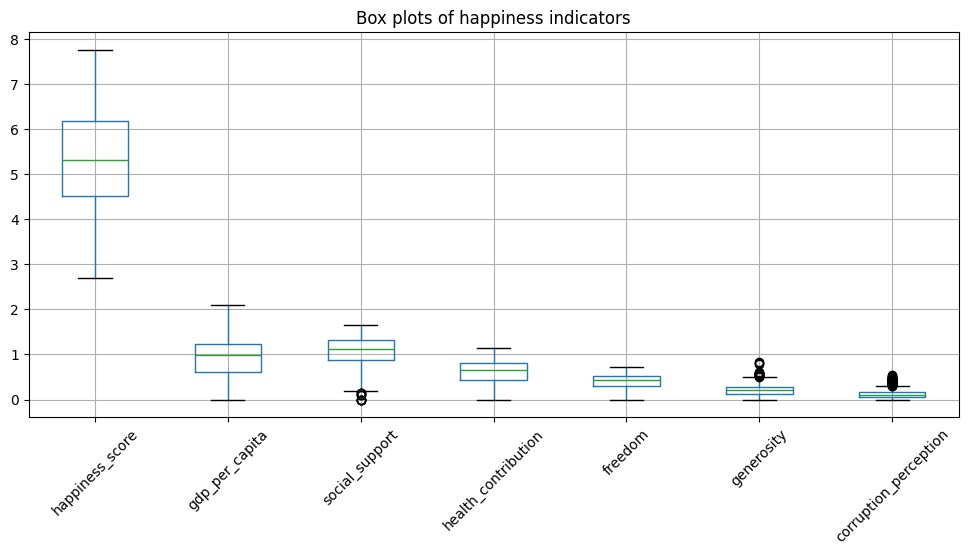

In [ ]:
happiness[ numeric_columns ].boxplot(figsize=(12, 5), rot=45)
plt.title("Box plots of happiness indicators")
plt.show()

In [ ]:
for column in numeric_columns:
    q1 = happiness[column].quantile(0.25)
    q3 = happiness[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outlier_count = ((happiness[column] < lower_limit) |
                     (happiness[column] > upper_limit)).sum()
    print(column, "possible outliers:", outlier_count)

happiness_score possible outliers: 0
gdp_per_capita possible outliers: 0
social_support possible outliers: 10
health_contribution possible outliers: 0
freedom possible outliers: 0
generosity possible outliers: 17
corruption_perception possible outliers: 68


## 10. Clean the life expectancy dataset
The life expectancy file contains many years. We only need 2015–2019 to match the happiness data. We rename its columns and remove rows that represent regions or groups rather than individual countries by keeping three-letter country codes.

In [23]:
life = life_raw.rename(columns={
    "Entity": "country",
    "Code": "country_code",
    "Year": "year",
    "Life expectancy": "life_expectancy"
})

life = life[life["year"].isin([2015, 2016, 2017, 2018, 2019])]
life = life.dropna(subset=["country_code"])

In [25]:
life = life[life["country_code"].str.len() == 3]
life["country"] = life["country"].str.strip()
life["year"] = life["year"].astype(int)

In [26]:
life = life.drop_duplicates(subset=["country", "year"])
life = life[["country", "country_code", "year", "life_expectancy"]]

print("Life expectancy data after cleaning:", life.shape)
display(life.head())

Life expectancy data after cleaning: (1180, 4)


,country,country_code,year,life_expectancy
65,Afghanistan,AFG,2015,62.2695
66,Afghanistan,AFG,2016,62.6459
67,Afghanistan,AFG,2017,62.4062
68,Afghanistan,AFG,2018,62.4434
69,Afghanistan,AFG,2019,62.9411


## 11. Combine the two data sources
Before merging, we check country names that appear in the happiness data but not in the life expectancy data. A small number of country names may be written differently in the two sources. We standardise some common differences and then merge using country and year.

In [ ]:
name_changes = {
    "Czech Republic": "Czechia",
    "Macedonia": "North Macedonia",
    "Ivory Coast": "Cote d'Ivoire",
    "Swaziland": "Eswatini",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong"
}

happiness["country"] = happiness["country"].replace(name_changes)
life["country"] = life["country"].replace(name_changes)

not_matched = set(happiness["country"]) - set(life["country"])
print("Country names without a match:")
print(sorted(not_matched))

Country names without a match:
['Congo (Brazzaville)', 'Congo (Kinshasa)', 'Kosovo', 'North Cyprus', 'Northern Cyprus', 'Palestinian Territories', 'Somaliland Region', 'Somaliland region']


### 11.1 Merge using a left join
A left join keeps all records from the happiness dataset and adds life expectancy information when a matching country and year are available.

In [27]:
combined = pd.merge(
    happiness,
    life,
    on=["country", "year"],
    how="left"
)

print("Happiness rows before merge:", len(happiness))
print("Rows after merge:", len(combined))
print("Missing life expectancy values:", combined["life_expectancy"].isnull().sum())
display(combined.head())

Happiness rows before merge: 782
Rows after merge: 782
Missing life expectancy values: 47


,country,region,year,happiness_score,gdp_per_capita,social_support,health_contribution,freedom,generosity,corruption_perception,country_code,life_expectancy
0,Switzerland,Western Europe,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,CHE,82.8461
1,Iceland,Western Europe,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,ISL,82.1638
2,Denmark,Western Europe,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,DNK,80.7394
3,Norway,Western Europe,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,NOR,82.2728
4,Canada,North America,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,CAN,81.9084


## 12. Data transformation
create a simple happiness category from the happiness score. The categories are based on the score ranges in this combined dataset. We also sort the rows by country and year.

In [ ]:
combined["happiness_category"] = pd.cut(
    combined["happiness_score"],
    bins=[0, 4, 6, 10],
    labels=["Low", "Medium", "High"]
)

combined = combined.sort_values(["country", "year"])
combined = combined.reset_index(drop=True)

display(combined[["country", "year", "happiness_score", "happiness_category"]].head(10))

,country,year,happiness_score,happiness_category
0,Afghanistan,2015,3.575,Low
1,Afghanistan,2016,3.360,Low
2,Afghanistan,2017,3.794,Low
3,Afghanistan,2018,3.632,Low
4,Afghanistan,2019,3.203,Low
5,Albania,2015,4.959,Medium
6,Albania,2016,4.655,Medium
7,Albania,2017,4.644,Medium
8,Albania,2018,4.586,Medium
9,Albania,2019,4.719,Medium


## 13. Grouping and summarising data
`groupby()` is used to calculate average happiness and life expectancy for each year. Missing life expectancy values are automatically ignored when calculating the mean.

In [ ]:
year_summary = combined.groupby("year").agg(
    average_happiness=("happiness_score", "mean"),
    average_life_expectancy=("life_expectancy", "mean"),
    number_of_countries=("country", "nunique")
)

display(year_summary.round(2))

,average_happiness,average_life_expectancy,number_of_countries
year,,,
2015,5.38,72.05,158
2016,5.38,72.42,157
2017,5.35,72.29,155
2018,5.38,72.68,156
2019,5.41,72.76,156


## 14. Reshaping data: Pivot and Melt
Pivot changes the happiness data from long format to wide format. Melt changes it back to long format. These are basic examples of data reshaping.

In [ ]:
happiness_wide = combined.pivot_table(
    index="country", columns="year", values="happiness_score"
)

display(happiness_wide.head())

year,2015,2016,2017,2018,2019
country,,,,,
Afghanistan,3.575,3.360,3.794,3.632,3.203
Albania,4.959,4.655,4.644,4.586,4.719
Algeria,5.605,6.355,5.872,5.295,5.211
Angola,4.033,3.866,3.795,3.795,NaN
Argentina,6.574,6.650,6.599,6.388,6.086


In [ ]:
happiness_long = happiness_wide.reset_index().melt(
    id_vars="country",
    var_name="year",
    value_name="happiness_score"
)

display(happiness_long.head())

,country,year,happiness_score
0,Afghanistan,2015,3.575
1,Albania,2015,4.959
2,Algeria,2015,5.605
3,Angola,2015,4.033
4,Argentina,2015,6.574


## 15. Final data validation
Check the final number of rows, columns, data types and missing values. The life expectancy column may still contain missing values when a country-year could not be matched. We keep these missing values rather than replacing them with an unrelated value.

In [ ]:
print("Final dataset shape:", combined.shape)
print("\nMissing values:")
print(combined.isnull().sum())
print("\nDuplicate country-year rows:",
      combined.duplicated(subset=["country", "year"]).sum())
combined.info()

Final dataset shape: (782, 13)

Missing values:
country                   0
region                    0
year                      0
happiness_score           0
gdp_per_capita            0
social_support            0
health_contribution       0
freedom                   0
generosity                0
corruption_perception     0
country_code             27
life_expectancy          27
happiness_category        0
dtype: int64

Duplicate country-year rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   country                782 non-null    object  
 1   region                 782 non-null    object  
 2   year                   782 non-null    int64   
 3   happiness_score        782 non-null    float64 
 4   gdp_per_capita         782 non-null    float64 
 5   social_support         782 non-null    float64 
 6   health_co

## 16. Save the cleaned dataset


In [ ]:
combined.to_csv("happiness_life_expectancy_clean.csv", index=False)
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [ ]:
# Run this cell in Google Colab to download the cleaned CSV file.
from google.colab import files
files.download("happiness_life_expectancy_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>